# New England Site Index Analysis

**Summary:** This analysis explores the relationship between site index and soil properties in New England. The goal is to identify deficiencies in current SSURGO site index data in New England. To accomplish this, a predictive model for site index is developed using soil properties. Site index and soil property data are sourced from SSURGO. The premise of this analysis is that the predominant relationships between site index and soil properties will allow for aberrant observations of of site index for the given soil properties to be identified as potential errors in the SSURGO data.

The analysis below demonstrates this workflow for eastern white pine.

The analysis uses the following predictor variables:

-   depth to root restrictive layer (e.g., bedrock or densic)

-   AWC (available water capacity) above root restrictive layer (ARRL)

-   combined silt & very fine sand percent ARRL

-   rock fragment volume ARRL

-   drainage class

-   soil order

-   temperature regime

------------------------------------------------------------------------

import necessary libraries:

In [1]:
import pandas as pd
import numpy as np
import asyncio
from soildb import SDAClient, Query
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, RepeatedKFold
from sklearn.model_selection import cross_validate, KFold
from sklearn.base import clone
import shap

Access soil property data for all major components with eastern white pine in the component forest productivity table:

In [2]:
async def get_from_sda():
    client = SDAClient()
    
    new_england_fips = ("CT", "ME", "MA", "NH", "RI", "VT")
    
    # Single query for all matching components across New England
    query = (
        Query()
        .select(
            "l.areasymbol", 
            "mu.mukey", 
            "c.compname",
            "c.taxorder",
            "c.taxtempregime",
            "c.drainagecl",
            "c.cokey",
            "ch.desgnmaster",
            "ch.hzname",
            "ch.hzthk_r",
            "ch.hzdept_r",
            "ch.hzdepb_r",
            "ch.sandtotal_r",
            "ch.sandvf_r",
            "ch.silttotal_r",
            "ch.claytotal_r",
            "ch.fragvoltot_r",
            "ch.awc_r",
            "ch.caco3_r",
            "ch.sumbases_r",
            "ch.cokey",
            "ch.chkey"
        )
        .from_("component as c")
        .inner_join("chorizon as ch", "c.cokey = ch.cokey")
        .inner_join("mapunit as mu", "c.mukey = mu.mukey")
        .inner_join("legend as l", "mu.lkey = l.lkey")
        .where("c.majcompflag = 'Yes'")
        .where("c.compkind = 'series'")
        .where(f"LEFT(l.areasymbol, 2) IN {new_england_fips}")
    )
    
    # Execute and return the pandas dataframe directly
    result = await client.execute(query)
    return result.to_pandas()

# Execute the function
df = await get_from_sda()

Access rock fragment data separately due to the large number of rows returned from rock fragment query:

In [3]:
import pandas as pd
from soildb.client import SDAClient, Query  # Ensure correct imports

async def get_all_ne_maj_series():
    client = SDAClient()
    new_england_states = ("CT", "ME", "MA", "NH", "RI", "VT") # Added NY from your upper function
    dfs = []

    for state in new_england_states:
        print(f"Fetching data for {state}...")

        # Fixed: Added chorizon (ch) so we can join on ch.chkey
        query = (
            Query()
            .select(
                "c.cokey",
                "ch.chkey",
                "chf.fragvol_r",
                "chf.fragkind",
                "chf.fragsize_r",
                "chf.fragshp"
            )
            .from_("component as c")
            .inner_join("mapunit as mu", "c.mukey = mu.mukey")
            .inner_join("coforprod as cp", "c.cokey = cp.cokey")
            .inner_join("legend as l", "mu.lkey = l.lkey")
            .inner_join("chorizon as ch", "c.cokey = ch.cokey")
            .left_join("chfrags as chf", "ch.chkey = chf.chkey")
            .where("cp.plantcomname = 'eastern white pine'")
            .where(f"LEFT(l.areasymbol, 2) = '{state}'")
        )    

        # Fixed: Kept inside the loop indentation
        try:
            result = await client.execute(query)
            state_df = result.to_pandas()
            dfs.append(state_df)
        except Exception as e:
            print(f"Failed to fetch data for {state}: {e}")
            
    # Combine all individual state dataframes into one master dataframe
    if dfs:
        return pd.concat(dfs, ignore_index=True)
    else:
        return pd.DataFrame()

# Execute the function
df_frag = await get_all_ne_maj_series()

Fetching data for CT...
Fetching data for ME...
Fetching data for MA...
Fetching data for NH...
Fetching data for RI...
Fetching data for VT...


Acess site index data for all major components with eastern white pine in the component forest productivity table:

In [4]:
async def get_from_sda():
    client = SDAClient()
    
    new_england_fips = ("CT", "ME", "MA", "NH", "RI", "VT")
    
    # Single query for all matching components across New England
    query = (
        Query()
        .select(
            "c.cokey",
            "l.areasymbol", 
            "mu.mukey", 
            "mu.muacres", 
            "c.compname", 
            "c.comppct_r", 
            "cp.plantcomname", 
            "cp.siteindex_r"
        )
        .from_("component as c")
        .inner_join("mapunit as mu", "c.mukey = mu.mukey")
        .inner_join("coforprod as cp", "c.cokey = cp.cokey")
        .inner_join("legend as l", "mu.lkey = l.lkey")
        .where("cp.plantcomname = 'eastern white pine'")
        .where(f"LEFT(l.areasymbol, 2) IN {new_england_fips}")
    )
    
    # Execute and return the pandas dataframe directly
    result = await client.execute(query)
    return result.to_pandas()

# Execute the function
df_si = await get_from_sda()

Create desired predictor variables:

In [5]:
# sort components by hz depth (they should be already)
df = df.sort_values(['cokey', 'hzdept_r'])

# restrictive features
df['is_res'] = df['hzname'].str.contains('d|R|m|x')

# flag restrictions and every horizon below it
df['res_or_below'] = df.groupby('cokey')['is_res'].cummax()

# add frag volumes across fragment sizes and types
df_frag_agg = df_frag.groupby('chkey').agg(
    frag_vol_tot = ('fragvol_r', 'sum'))

# left join aggregated frag data to respective component horizon
df = pd.merge(df, df_frag_agg,
                how = 'left',
                on = 'chkey')

# remove res and below
df_above = df[~df['res_or_below']].copy()

# hz thickness
df_above['hz_thk'] = df_above['hzdepb_r'] - df_above['hzdept_r']

# hz awc vol
df_above['hz_awc_vol'] = df_above['hz_thk'] * df_above['awc_r']

# calculate awc, silt/vfs, and frags above restriction
summary_df = df_above.groupby('cokey').apply(
    lambda g: pd.Series({
        'res_dept' : g['hzdepb_r'].max(),
        'awc_above_res' : g['hz_awc_vol'].sum(),
        'silt_vfs_wtavg' : ((g['sandvf_r'] + g['silttotal_r']) * g['hz_thk']).sum() / g['hz_thk'].sum(),
        'frag_vol_wtavg' : (g['frag_vol_tot'] * g['hz_thk']).sum() / g['hz_thk'].sum()
    })
)

# add drainage, order, temp to summary df
summary_df = pd.merge(summary_df, 
         df[['cokey', 'drainagecl', 'taxorder', 'taxtempregime']].drop_duplicates(),
         how = 'inner',
         on = 'cokey')

# add site index values to summary df
summary_prop_si = pd.merge(summary_df,
         df_si,
         on = 'cokey',
         how = 'inner')

Components are grouped by component name and properties are aggregated with mean or mode as appropriate:

In [6]:
comp_si_agg = summary_prop_si.groupby('compname').agg(
    res_dept = ('res_dept', 'mean'),
    awc_above_res = ('awc_above_res', 'mean'),
    drainagecl = ('drainagecl', lambda x: x.mode().iloc[0]),
    taxorder = ('taxorder', lambda x: x.mode().iloc[0]),
    taxtempregime = ('taxtempregime', lambda x: x.mode().iloc[0]),
    silt_vfs_wtavg = ('silt_vfs_wtavg', 'mean'),
    frag_vol_wtavg = ('frag_vol_wtavg', 'mean'),
    site_index = ('siteindex_r', 'mean')
).reset_index()

Remove non-representative series:

In [7]:
# Non-representative series

# Martha's Vineyard
comp_si_agg = comp_si_agg[~comp_si_agg['compname'].isin(['Chilmark'])]
# Cape Cod / Martha's Vineyard
comp_si_agg = comp_si_agg[~comp_si_agg['compname'].isin(['Eastchop'])]
# Cape Cod
comp_si_agg = comp_si_agg[~comp_si_agg['compname'].isin(['Barnstable'])]
# Dredge spoils
comp_si_agg = comp_si_agg[~comp_si_agg['compname'].isin(['Fortress'])]
# Dredge spoils
comp_si_agg = comp_si_agg[~comp_si_agg['compname'].isin(['Bigapple'])]

Change component site index values for components that have been recognized as having inaccarate values:

In [8]:
comp_si_agg.loc[comp_si_agg['compname'] == 'Rawsonville', 'site_index'] = 67
comp_si_agg.loc[comp_si_agg['compname'] == 'Adamant', 'site_index'] = 67
comp_si_agg.loc[comp_si_agg['compname'] == 'Newfields', 'site_index'] = 67
comp_si_agg.loc[comp_si_agg['compname'] == 'Schroon', 'site_index'] = 67
comp_si_agg.loc[comp_si_agg['compname'] == 'Skerry', 'site_index'] = 67
comp_si_agg.loc[comp_si_agg['compname'] == 'Knob Lock', 'site_index'] = 55

Remove predictors we don't want to use in the model:

In [9]:
# awc is correlated with most other predictors (creates multicollinearity issues) and does not improve performance compared to models without it
comp_si_agg = comp_si_agg.drop(columns = ['awc_above_res'])

# awc is correlated with most other predictors (creates multicollinearity issues) and does not improve performance compared to models without it
comp_si_agg = comp_si_agg.drop(columns = ['taxorder', 'taxtempregime'])

Prepare data for modeling: 

In [10]:
# remove rows with missing values
comp_si_agg = comp_si_agg.dropna()

# assign drainage class ordinals
drainage_mapping = {
    "Very poorly drained": 0,
    "Poorly drained": 1,
    "Somewhat poorly drained": 2,
    "Moderately well drained": 3,
    "Well drained": 4,
    "Somewhat excessively drained": 5,
    "Excessively drained": 6,
}
comp_si_agg["drainagecl"] = comp_si_agg["drainagecl"].map(drainage_mapping)

# separate features and target
X = comp_si_agg.drop(columns=["site_index", "compname"])
y = comp_si_agg["site_index"]

# encode nominal categorical variables with one-hot encoding
X_encoded = X

Optimize random forest hyperparameters with grid search and cross validation:

In [11]:
# define the parameters to search over
param_grid = {
    'max_depth': [3, 4, 5, 6, None],
    'min_samples_leaf': [2, 3, 4, 5, 7]
}

# set up a repeated cross-validation strategy
# n_splits=5 means 80/20 train/test splits, n_repeats=5 runs it 5 separate random times for each split, for a total of 25 runs.
repeated_cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=32)

# build the Grid Search with the repeated runs
# calculate multiple metrics (R2, MAE, RMSE) but still pick the final "winner" based on R2
grid_search = GridSearchCV(
    estimator=RandomForestRegressor(n_estimators=300, random_state=64),
    param_grid=param_grid,
    cv=repeated_cv,
    scoring={
        'r2': 'r2',
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error'
    },
    refit='r2', # The grid search will still pick the final "winner" based on R2
    n_jobs=1
)

# fit using full dataset (X_encoded, y)
# repeated CV handles its own train/test splits internally across all 25 runs
grid_search.fit(X_encoded, y)

# extract the top-performing settings
print("Best Parameters:", grid_search.best_params_)
print("Highest Average Test R² Score:", round(grid_search.best_score_, 4))

Best Parameters: {'max_depth': 4, 'min_samples_leaf': 2}
Highest Average Test R² Score: 0.4359


Confirm that R2, MAE, and RMSE have reasonable agreement:

In [12]:
# convert the multi-metric cv_results_ into a DataFrame
results_df = pd.DataFrame(grid_search.cv_results_)

# extract the columns for R², MAE, and RMSE
columns_to_keep = [
    'param_max_depth', 
    'param_min_samples_leaf', 
    'mean_test_r2',
    'std_test_r2',
    'mean_test_mae',
    'mean_test_rmse'
]

# create a clean subset table
multi_metrics_df = results_df[columns_to_keep].copy()

# convert negative scores back to intuitive positive error values
multi_metrics_df['mean_test_mae'] = -multi_metrics_df['mean_test_mae']
multi_metrics_df['mean_test_rmse'] = -multi_metrics_df['mean_test_rmse']

# sort by R² score (highest first) to match your refit parameter
sorted_metrics = multi_metrics_df.sort_values(by='mean_test_r2', ascending=False)

# display the results
print(sorted_metrics.to_string(index=False))

param_max_depth  param_min_samples_leaf  mean_test_r2  std_test_r2  mean_test_mae  mean_test_rmse
              4                       2      0.435873     0.060511       4.164553        5.152862
              5                       2      0.435471     0.068437       4.153514        5.150053
              4                       3      0.431938     0.061895       4.178576        5.169973
              5                       3      0.430189     0.069917       4.177578        5.173568
              6                       2      0.429250     0.073028       4.168534        5.176293
              4                       4      0.429015     0.062410       4.194123        5.182683
              4                       5      0.427582     0.063567       4.200750        5.188270
              5                       4      0.426262     0.071045       4.198729        5.190335
              5                       5      0.423773     0.071309       4.212108        5.200799
              6     

In [13]:
import shap
from sklearn.base import clone
from sklearn.model_selection import KFold

# best estimator from grid search
# because GridSearchCV is using refit='r2', this is already fit on the full dataset
best_rf_model = grid_search.best_estimator_

# one split per aggregated compname row
# those same held-out compnames will also be used to score summary_prop_si safely
simple_cv = KFold(n_splits=5, shuffle=True, random_state=32)

# storage aligned to comp_si_agg / X_encoded row order
oof_predictions = pd.Series(index=X_encoded.index, dtype=float, name="oof_prediction")
oof_shap_values = pd.DataFrame(
    index=X_encoded.index,
    columns=X_encoded.columns,
    dtype=float
)
oof_base_values = pd.Series(index=X_encoded.index, dtype=float, name="shap_base_value")

# row-level table for leakage-safe predictions on the larger dataframe
detail_df = summary_prop_si.copy()
detail_df["drainagecl"] = detail_df["drainagecl"].map(drainage_mapping)
detail_df = detail_df.drop(columns=["awc_above_res", "taxorder", "taxtempregime"], errors="ignore")

# match the training design matrix exactly
detail_X = detail_df.reindex(columns=X_encoded.columns)

# only compnames that survived all comp_si_agg filtering can receive OOF detail predictions
eligible_compnames = set(comp_si_agg["compname"])
detail_valid_mask = detail_df["compname"].isin(eligible_compnames) & detail_X.notna().all(axis=1)

detail_oof_pred = pd.Series(index=detail_df.index, dtype=float, name="detail_oof_prediction")

fold_feature_importances = []
fold_models = []

for fold, (train_idx, test_idx) in enumerate(simple_cv.split(X_encoded, y), start=1):
    X_train = X_encoded.iloc[train_idx]
    X_test = X_encoded.iloc[test_idx]
    y_train = y.iloc[train_idx]

    # each test row is one held-out compname in the aggregated table
    held_out_compnames = comp_si_agg.iloc[test_idx]["compname"]

    # clone keeps the tuned hyperparameters but drops the fitted state
    fold_model = clone(best_rf_model)
    fold_model.fit(X_train, y_train)
    fold_models.append(fold_model)

    # out-of-fold predictions on the aggregated table
    fold_preds = fold_model.predict(X_test)
    oof_predictions.iloc[test_idx] = fold_preds

    # Gini importance for this fold
    fold_feature_importances.append(fold_model.feature_importances_)

    # out-of-fold SHAP values for the held-out aggregated rows
    explainer = shap.TreeExplainer(fold_model)
    fold_explanation = explainer(X_test)

    oof_shap_values.iloc[test_idx, :] = fold_explanation.values

    fold_base = np.asarray(fold_explanation.base_values)
    if fold_base.ndim == 0:
        fold_base = np.repeat(fold_base, len(test_idx))
    else:
        fold_base = fold_base.reshape(-1)

    oof_base_values.iloc[test_idx] = fold_base

    # score only detail rows whose compname is held out in this fold
    detail_mask = detail_df["compname"].isin(held_out_compnames) & detail_valid_mask
    detail_oof_pred.loc[detail_mask] = fold_model.predict(detail_X.loc[detail_mask])

# add OOF predictions back to comp_si_agg
comp_si_agg = comp_si_agg.copy()
comp_si_agg["oof_prediction"] = oof_predictions
comp_si_agg["oof_residual"] = comp_si_agg["site_index"] - comp_si_agg["oof_prediction"]
comp_si_agg["shap_base_value"] = oof_base_values

# add one SHAP contribution column per predictor for each OOF prediction
oof_shap_values_for_export = oof_shap_values.add_prefix("shap_")
comp_si_agg = pd.concat([comp_si_agg, oof_shap_values_for_export], axis=1)

# add leakage-safe predictions back to the larger dataframe
detail_df["detail_oof_prediction"] = detail_oof_pred
detail_df["detail_oof_residual"] = detail_df["siteindex_r"] - detail_df["detail_oof_prediction"]

# averaged fold Gini importance
fold_feature_importances = np.vstack(fold_feature_importances)

gini_importance_df = (
    pd.DataFrame({
        "Feature": X_encoded.columns,
        "Mean_Gini_Importance": fold_feature_importances.mean(axis=0),
        "Std_Gini_Importance": fold_feature_importances.std(axis=0)
    })
    .sort_values("Mean_Gini_Importance", ascending=False)
    .reset_index(drop=True)
)

# combined SHAP object for plotting
oof_shap_explanation = shap.Explanation(
    values=oof_shap_values.to_numpy(),
    base_values=oof_base_values.to_numpy(),
    data=X_encoded.to_numpy(),
    feature_names=X_encoded.columns.tolist()
)

# optional check: SHAP values should reconstruct the OOF prediction
shap_reconstructed = oof_base_values + oof_shap_values.sum(axis=1)
print(
    "SHAP reconstructs OOF predictions:",
    np.allclose(shap_reconstructed.values, oof_predictions.values)
)

print(
    "Detail rows with OOF predictions:",
    detail_df["detail_oof_prediction"].notna().sum(),
    "of",
    len(detail_df)
)

# final full-data model for new predictions
# grid_search.best_estimator_ is already the full-data fitted model because refit='r2'
final_rf_model = best_rf_model

# example: predictions from the final model on the modeling data
comp_si_agg["final_model_prediction"] = final_rf_model.predict(X_encoded)

print(gini_importance_df)

SHAP reconstructs OOF predictions: True
Detail rows with OOF predictions: 6947 of 7031
          Feature  Mean_Gini_Importance  Std_Gini_Importance
0      drainagecl              0.487490             0.039490
1        res_dept              0.264636             0.026262
2  silt_vfs_wtavg              0.159129             0.024983
3  frag_vol_wtavg              0.088745             0.018264


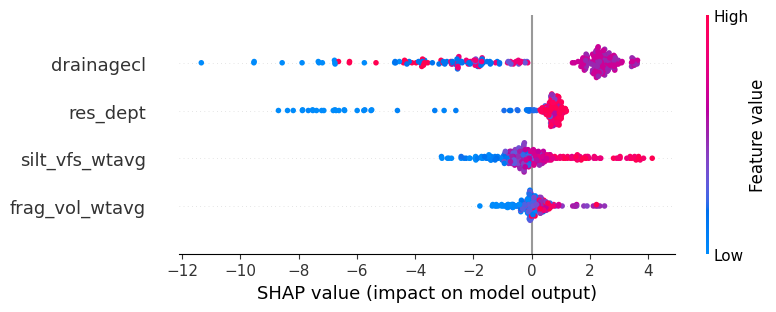

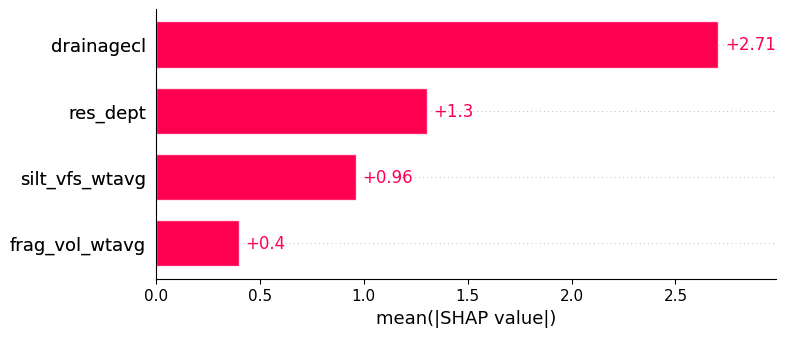

In [14]:
# optional SHAP plots
shap.plots.beeswarm(oof_shap_explanation)
shap.plots.bar(oof_shap_explanation)

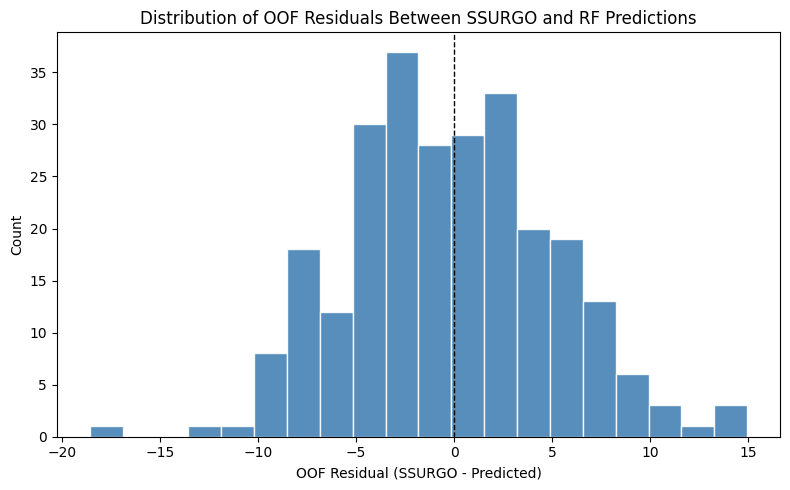

In [15]:
import matplotlib.pyplot as plt

residuals = comp_si_agg["oof_residual"].dropna()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(residuals, bins=20, color="steelblue", edgecolor="white", alpha=0.9)
ax.axvline(0, color="black", linestyle="--", linewidth=1)

ax.set_title("Distribution of OOF Residuals Between SSURGO and RF Predictions")
ax.set_xlabel("OOF Residual (SSURGO - Predicted)")
ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

In [16]:
comp_detail_diff = detail_df.groupby("compname").apply(
    lambda g: g["detail_oof_prediction"].min() - g["detail_oof_prediction"].max()
).sort_values().reset_index(name="prediction_diff")

In [17]:
w5 = pd.read_csv(r"D:\NE_site_index\Rue_data\W5_NewEngland.csv")
w5 = w5[w5["Species"] == "eastern white pine"].groupby(["SoilSeries", "PlotID", "Species"]).agg(plot_siteindex_mean=("SiteIndex", "mean")).reset_index()
w5_comp_agg = w5.groupby("SoilSeries").agg(plot_siteindex_mean=("plot_siteindex_mean", "mean"),
                                           plot_count=("PlotID", "count")).reset_index()
w5_comp_agg = w5_comp_agg[w5_comp_agg["plot_count"] >= 5]

In [18]:
comp_si_agg_w5 = pd.merge(comp_si_agg, w5_comp_agg, left_on="compname", right_on="SoilSeries", how="inner")

In [19]:
comp_si_agg_w5['ssurgo_minus_w5'] = comp_si_agg_w5['site_index'] - comp_si_agg_w5['plot_siteindex_mean']
comp_si_agg_w5['rf_minus_w5'] = comp_si_agg_w5['oof_prediction'] - comp_si_agg_w5['plot_siteindex_mean']

<Axes: >

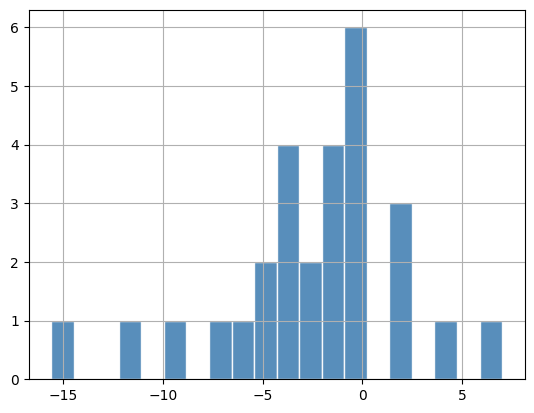

In [20]:
comp_si_agg_w5['ssurgo_minus_w5'].hist(bins=20, color="steelblue", edgecolor="white", alpha=0.9)

<Axes: >

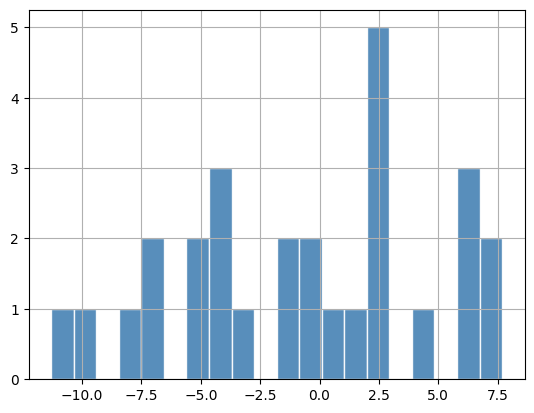

In [21]:
comp_si_agg_w5['rf_minus_w5'].hist(bins=20, color="steelblue", edgecolor="white", alpha=0.9)

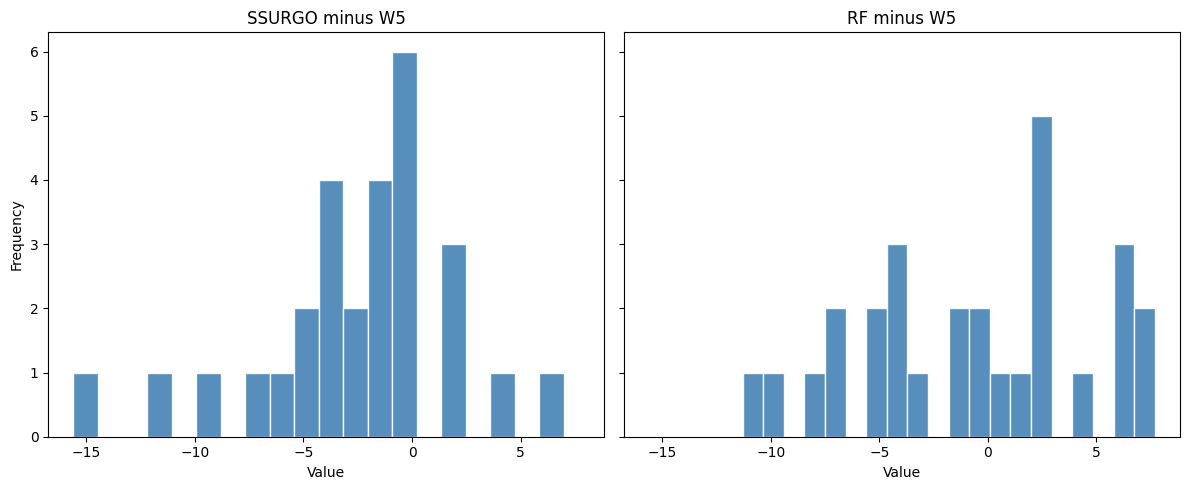

In [22]:
import matplotlib.pyplot as plt

# Create side-by-side subplots with shared x and y axes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# Plot the first histogram
comp_si_agg_w5['ssurgo_minus_w5'].hist(bins=20, color="steelblue", edgecolor="white", alpha=0.9, ax=ax1)
ax1.set_title('SSURGO minus W5')
ax1.set_xlabel('Value')
ax1.set_ylabel('Frequency')
ax1.grid(False) # Optional: turns off the default background grid

# Plot the second histogram
comp_si_agg_w5['rf_minus_w5'].hist(bins=20, color="steelblue", edgecolor="white", alpha=0.9, ax=ax2)
ax2.set_title('RF minus W5')
ax2.set_xlabel('Value')
ax2.grid(False) # Optional: turns off the default background grid

# Adjust layout to prevent overlapping labels
plt.tight_layout()
plt.show()


In [23]:
comp_detail_diff.to_csv(r"D:\NE_site_index\scripts\python\ne_county_prism\comp_detail_diff.csv", index=True)

In [24]:
detail_df.to_csv(r"D:\NE_site_index\scripts\python\ne_county_prism\detail_df_with_oof_predictions.csv", index=False)

In [25]:
comp_si_agg.to_csv(r"D:\NE_site_index\scripts\python\ne_county_prism\comp_si_agg_with_oof_predictions.csv", index=False)

In [26]:
comp_si_agg_w5.to_csv(r"D:\NE_site_index\scripts\python\ne_county_prism\comp_si_agg_with_w5.csv", index=False)

In [23]:
import joblib

# Assuming 'model' is your trained RandomForestClassifier or RandomForestRegressor
joblib.dump(final_rf_model, 'random_forest_model.pkl')


['random_forest_model.pkl']